# Assignment 11: Layer-wise BERT probing

This notebook evaluates which `bert-base-uncased` encoder layer represents sentence length, bigram shift, and subject number. For every task, it creates a balanced sample, performs a stratified 90:10 split, extracts `[CLS]` representations from all 12 encoder layers, and fits a logistic-regression probe per layer.

The full model experiment is opt-in because it downloads several hundred MB and performs 36 inference/classification runs. Set `RUN_MODEL_EVALUATION = True` after installing the packages in the README.

In [1]:
from pathlib import Path
from typing import Dict, List, Tuple
import hashlib
import json
import re
import urllib.request

import numpy as np
import pandas as pd

SAMPLE_SIZE = 50_000
TEST_SIZE = 0.10
RANDOM_STATE = 42
MAX_LENGTH = 128
RUN_MODEL_EVALUATION = True
BATCH_SIZE = 32
ROOT = Path.cwd()
if ROOT.name != "Assignment - 11" and (ROOT / "Assignment - 11").is_dir():
    ROOT = ROOT / "Assignment - 11"
DATA_DIR = ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
TASK_URLS = {
    "sentence_length": "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/sentence_length.txt",
    "bigram_shift": "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/bigram_shift.txt",
    "subj_number": "https://raw.githubusercontent.com/facebookresearch/SentEval/main/data/probing/subj_number.txt",
}
print(f"Data directory: {DATA_DIR.resolve()}")

Data directory: D:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\Assignment - 11\data


## 1. Download, parse, balance, and split the probing data

The parser accepts the tab-separated format used by SentEval (`split`, `label`, `sentence`) and also tolerates label-first variants. A balanced sample is made without replacement where possible. If a source file has fewer than 50,000 usable rows, the largest possible strictly balanced subset is used and its size is reported.

In [2]:
def download_task(name: str, url: str) -> Path:
    target = DATA_DIR / f"{name}.txt"
    if not target.exists():
        urllib.request.urlretrieve(url, target)
    return target


def parse_task(path: Path) -> pd.DataFrame:
    rows = []
    for raw_line in path.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line:
            continue
        fields = line.split("\t")
        if len(fields) < 2:
            fields = re.split(r"\s+", line, maxsplit=1)
        if len(fields) < 2:
            continue
        # SentEval probing files are split, label, sentence. Labels may be
        # numeric (0, 1, ...) or categorical (I, O, ...).
        if fields[0].strip().lower() in {"tr", "va", "te", "train", "valid", "test"} and len(fields) >= 3:
            label_index = 1
        elif len(fields) >= 2:
            label_index = 0
        else:
            continue
        label = fields[label_index].strip()
        if not label or label.lower() in {"label", "class", "target"}:
            continue
        sentence = " ".join(fields[label_index + 1:]).strip()
        if sentence:
            rows.append((label, sentence))
    frame = pd.DataFrame(rows, columns=["label", "sentence"])
    if frame.empty or frame["label"].nunique() < 2:
        raise ValueError(f"Could not parse at least two classes from {path}")
    return frame.drop_duplicates().reset_index(drop=True)


def balanced_sample(frame: pd.DataFrame, requested_size: int, seed: int) -> pd.DataFrame:
    counts = frame["label"].value_counts()
    per_class = min(requested_size // len(counts), int(counts.min()))
    if per_class < 1:
        raise ValueError("Every class needs at least one example")
    rng = np.random.default_rng(seed)
    pieces = [group.iloc[rng.choice(len(group), per_class, replace=False)]
              for _, group in frame.groupby("label", sort=True)]
    result = pd.concat(pieces, ignore_index=True)
    return result.sample(frac=1, random_state=seed).reset_index(drop=True)


def stratified_split(frame: pd.DataFrame) -> Tuple[pd.DataFrame, pd.DataFrame]:
    # Split each class independently so rounding cannot unbalance either
    # partition when the per-class count is not divisible by 10.
    train_parts, test_parts = [], []
    for label, group in frame.groupby("label", sort=True):
        shuffled = group.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
        test_count = max(1, int(round(len(shuffled) * TEST_SIZE)))
        test_parts.append(shuffled.iloc[:test_count])
        train_parts.append(shuffled.iloc[test_count:])
    train = pd.concat(train_parts, ignore_index=True)
    test = pd.concat(test_parts, ignore_index=True)
    return train.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True), test.sample(
        frac=1, random_state=RANDOM_STATE
    ).reset_index(drop=True)


datasets: Dict[str, Tuple[pd.DataFrame, pd.DataFrame]] = {}
summary = []
for task, url in TASK_URLS.items():
    raw = parse_task(download_task(task, url))
    sample = balanced_sample(raw, SAMPLE_SIZE, RANDOM_STATE)
    train, test = stratified_split(sample)
    datasets[task] = (train, test)
    summary.append({
        "task": task, "raw_rows": len(raw), "sample_rows": len(sample),
        "classes": sample["label"].nunique(), "train_rows": len(train),
        "test_rows": len(test), "train_min_class": train["label"].value_counts().min(),
        "test_min_class": test["label"].value_counts().min(),
    })
summary_df = pd.DataFrame(summary)
summary_df

,task,raw_rows,sample_rows,classes,train_rows,test_rows,train_min_class,test_min_class
0,sentence_length,48499,47688,3,42918,4770,14306,1590
1,bigram_shift,119631,50000,2,45000,5000,22500,2500
2,subj_number,119236,50000,2,45000,5000,22500,2500


In [3]:
# Lightweight, model-free sanity checks required by the assignment.
assert set(datasets) == set(TASK_URLS)
for task, (train, test) in datasets.items():
    combined = pd.concat([train, test])
    assert combined["label"].value_counts().nunique() == 1, task
    assert train["label"].value_counts().nunique() == 1, task
    assert test["label"].value_counts().nunique() == 1, task
    assert len(train) + len(test) == len(combined)
print("All tasks are balanced in the sample, training split, and test split.")

All tasks are balanced in the sample, training split, and test split.


## 2. Extract representations and train probes

The model returns the hidden states tuple containing the embedding output plus 12 encoder outputs. The embedding output is intentionally skipped, leaving exactly 12 representations. The classifier uses a multinomial logistic regression with a fixed solver and seed. Representations are cached per task and split.

In [4]:
def evaluate_layers(task: str, train: pd.DataFrame, test: pd.DataFrame) -> pd.DataFrame:
    try:
        import torch
        from sklearn.linear_model import LogisticRegression
        from sklearn.metrics import accuracy_score, f1_score
        from transformers import AutoModel, AutoTokenizer
        from tqdm.auto import tqdm
    except ModuleNotFoundError as error:
        raise ModuleNotFoundError(
            "Model evaluation needs torch, transformers, scikit-learn, and tqdm. "
            "Install them in this notebook's active kernel with: "
            "%pip install torch transformers scikit-learn tqdm matplotlib"
        ) from error

    model_name = "bert-base-uncased"
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name, output_hidden_states=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device).eval()

    def encode(sentences: List[str], split: str) -> np.ndarray:
        cache = DATA_DIR / f"{task}_{split}_representations.npy"
        if cache.exists():
            return np.load(cache)
        batches = []
        with torch.inference_mode():
            for start in tqdm(range(0, len(sentences), BATCH_SIZE), desc=f"{task}/{split}"):
                batch = tokenizer(sentences[start:start + BATCH_SIZE], padding=True,
                                  truncation=True, max_length=MAX_LENGTH,
                                  return_tensors="pt").to(device)
                hidden = model(**batch).hidden_states[1:]
                batches.append(torch.stack([layer[:, 0, :].cpu() for layer in hidden], dim=1))
        representations = torch.cat(batches).numpy()
        np.save(cache, representations)
        return representations

    x_train = encode(train["sentence"].tolist(), "train")
    x_test = encode(test["sentence"].tolist(), "test")
    results = []
    for layer in range(12):
        probe = LogisticRegression(max_iter=1000, solver="lbfgs", random_state=RANDOM_STATE)
        probe.fit(x_train[:, layer, :], train["label"])
        prediction = probe.predict(x_test[:, layer, :])
        results.append({"task": task, "layer": layer + 1,
                        "accuracy": accuracy_score(test["label"], prediction),
                        "macro_f1": f1_score(test["label"], prediction, average="macro")})
    return pd.DataFrame(results)


if RUN_MODEL_EVALUATION:
    results_df = pd.concat([
        evaluate_layers(task, train, test)
        for task, (train, test) in datasets.items()
    ], ignore_index=True)
    results_df.to_csv(DATA_DIR / "layer_probe_results.csv", index=False)
    results_df
else:
    print("RUN_MODEL_EVALUATION=False; data checks complete. Set it to True to run BERT probes.")

d:\SVNIT\Semester - 7\Introduction to Large Language Models\Practicals\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1022 14:36:35.326000 221976 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 757.91it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias        

task,bigram_shift,sentence_length,subj_number
layer,,,
1,0.505189,0.955909,0.802701
2,0.569381,0.975029,0.842390
3,0.639196,0.970636,0.846189
4,0.754593,0.964747,0.858797
5,0.811136,0.950359,0.881788
6,0.823331,0.934578,0.900784
7,0.822970,0.913748,0.887777
8,0.831794,0.905423,0.887980
9,0.856726,0.882248,0.886585


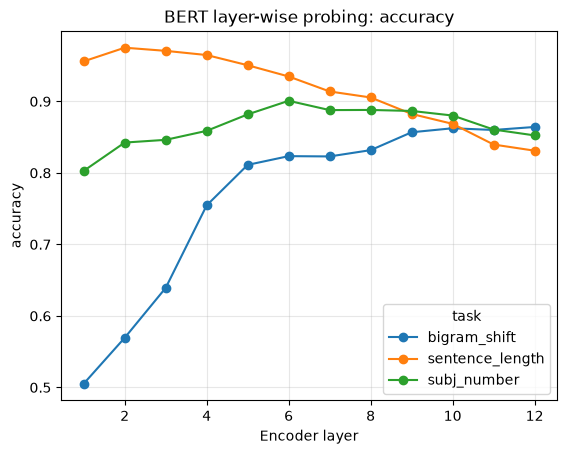

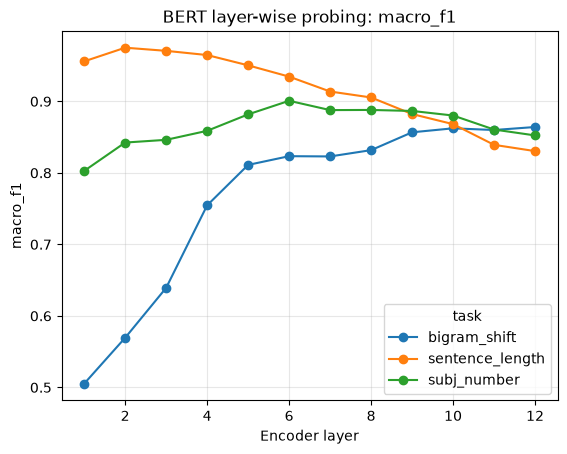

In [5]:
if RUN_MODEL_EVALUATION:
    import matplotlib.pyplot as plt
    display(results_df.pivot(index="layer", columns="task", values="macro_f1"))
    for metric in ["accuracy", "macro_f1"]:
        results_df.pivot(index="layer", columns="task", values=metric).plot(marker="o")
        plt.title(f"BERT layer-wise probing: {metric}")
        plt.xlabel("Encoder layer")
        plt.ylabel(metric)
        plt.grid(alpha=0.3)
        plt.show()
else:
    print("Plots are generated after model evaluation.")